Student Marks Prediction

In [1]:
conda install pandas matplotlib scikit-learn numpy

Channels:
 - defaults
Platform: win-64
Solving environment: ...working... done

## Package Plan ##

  environment location: C:\Users\chara\anaconda3

  added / updated specs:
    - matplotlib
    - numpy
    - pandas
    - scikit-learn


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    pandas-3.0.6               |  py314hf1216d0_0        12.3 MB
    scikit-learn-1.9.1         |  py314h9b39bef_0         8.3 MB
    ------------------------------------------------------------
                                           Total:        20.6 MB

The following packages will be UPDATED:

  pandas                              3.0.3-py314hf1216d0_0 --> 3.0.6-py314hf1216d0_0 
  scikit-learn                        1.9.0-py314h9b39bef_0 --> 1.9.1-py314h9b39bef_0 




Note: you may need to restart the kernel to use updated packages.


Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\chara\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\chara\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot import name 'CondaSubcommand' from 'conda.plugins' (C:\Users\chara\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-telemetry (cannot import name 'CondaRequestHeader' from 'conda.plugins' (C:\Users\chara\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: conda-anaconda-tos (cannot import name 'CondaPreCommand' from 'conda.plugins' (C:\Users\chara\anaconda3\Lib\site-packages\conda\plugins\__init__.py))
Error while loading conda entry point: repo (cannot

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

data = {
    "Study_Hours": [
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
        1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 11
    ],
    "Marks": [
        15, 20, 32, 35, 48, 55, 62, 72, 78, 88,
        18, 28, 30, 43, 50, 60, 70, 75, 85, 92
    ]
}

df = pd.DataFrame(data)

df.head()


,Study_Hours,Marks
0,1.0,15
1,2.0,20
2,3.0,32
3,4.0,35
4,5.0,48


In [4]:

print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())


Dataset shape: (20, 2)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Study_Hours  20 non-null     float64
 1   Marks        20 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 452.0 bytes

Statistical summary:


,Study_Hours,Marks
count,20.000000,20.000000
mean,5.775000,52.800000
std,3.002083,24.573413
min,1.000000,15.000000
25%,3.375000,31.500000
50%,5.750000,52.500000
75%,8.125000,72.750000
max,11.000000,92.000000


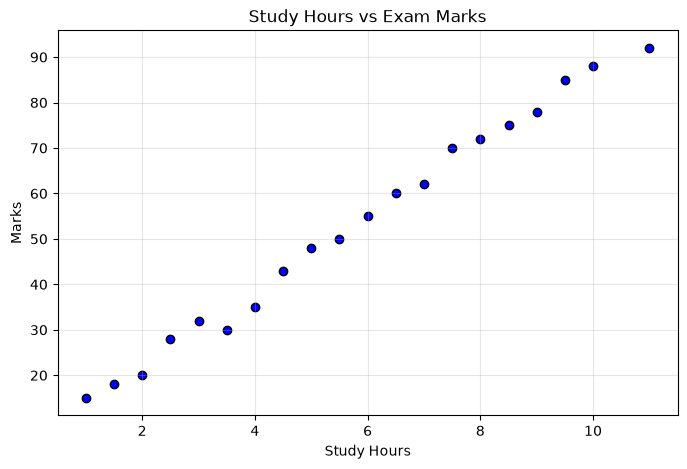

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Marks"],
    color="blue",
    edgecolor="black"
)

plt.title("Study Hours vs Exam Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.grid(True, alpha=0.3)
plt.show()


In [6]:

X = df[["Study_Hours"]]
y = df["Marks"]

print("Input features:")
display(X.head())

print("Target values:")
display(y.head())


Input features:


,Study_Hours
0,1.0
1,2.0
2,3.0
3,4.0
4,5.0


Target values:


0    15
1    20
2    32
3    35
4    48
Name: Marks, dtype: int64

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 16
Testing samples: 4


In [8]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")
print("Learned coefficient:", model.coef_[0])
print("Learned intercept:", model.intercept_)


Model training completed!
Learned coefficient: 8.136927899686516
Learned intercept: 5.790595611285298


In [9]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_Marks": y_test.values,
    "Predicted_Marks": np.round(y_pred, 2)
})

display(results)


,Actual_Marks,Predicted_Marks
0,15,13.93
1,75,74.95
2,60,58.68
3,20,22.06


In [10]:

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("R-squared Score:", round(r2, 3))


Mean Absolute Error: 1.13
R-squared Score: 0.997


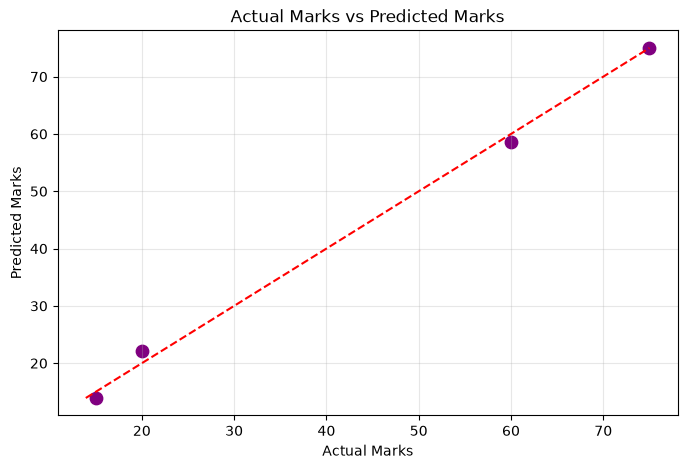

In [11]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="purple", s=80)

# Reference line for perfect predictions
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")

plt.title("Actual Marks vs Predicted Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.grid(True, alpha=0.3)
plt.show()


In [12]:

hours = float(input("Enter study hours: "))

if hours < 0:
    print("Study hours cannot be negative.")
else:
    new_data = pd.DataFrame({"Study_Hours": [hours]})
    predicted_marks = model.predict(new_data)[0]

    predicted_marks = max(0, min(100, predicted_marks))

    print("Estimated marks:", round(predicted_marks, 2))


Enter study hours:  6


Estimated marks: 54.61
